In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
pip install rasterio

In [ ]:
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image
import rasterio

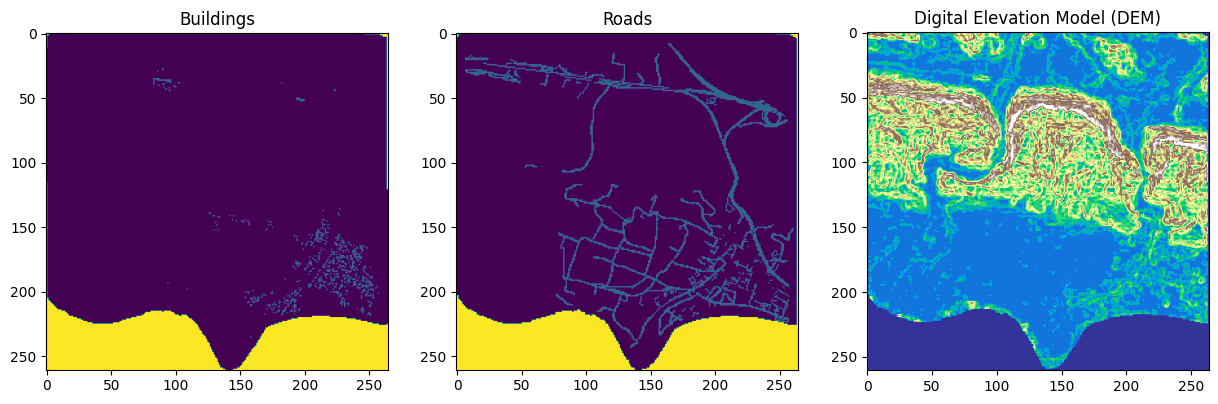

In [5]:
tif_image = Image.open("builds1.tif")
road_image = Image.open("RecRoads1.tif")
dem_image = Image.open("SlopeRec1.tif")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(tif_image)
axes[0].set_title('Buildings')

axes[1].imshow(road_image)
axes[1].set_title('Roads')

axes[2].imshow(dem_image, cmap='terrain')
axes[2].set_title('Digital Elevation Model (DEM)')

plt.show()

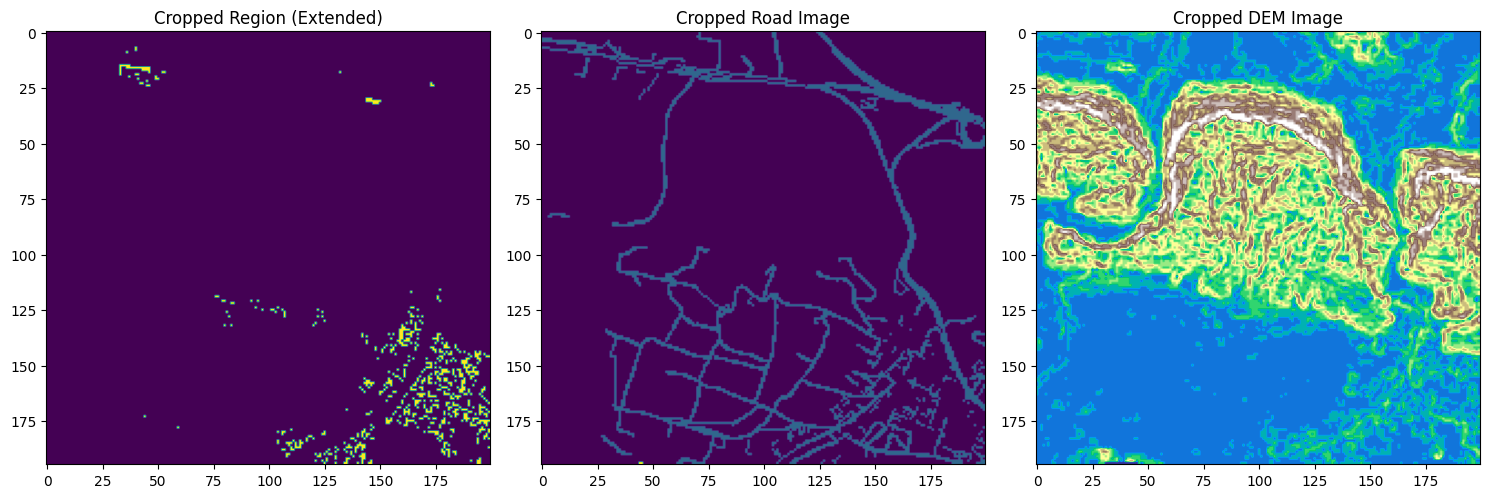

In [10]:
x_minb = 50
x_maxb = 250
y_minb = 20
y_maxb = 215

image_widthb, image_heightb = tif_image.size

x_min = 150
x_max = 250
y_min = 100
y_max = 200

image_width, image_height = tif_image.size

cropped_region_ext = tif_image.crop((x_minb, y_minb, min(x_maxb, image_width), min(y_maxb, image_height)))
cropped_road_image = road_image.crop((x_minb, y_minb, min(x_maxb, image_width), min(y_maxb, image_height)))
cropped_dem_image = dem_image.crop((x_minb, y_minb, min(x_maxb, image_width), min(y_maxb, image_height)))

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cropped_region_ext)
plt.title('Cropped Region (Extended)')

plt.subplot(1, 3, 2)
plt.imshow(cropped_road_image)
plt.title('Cropped Road Image')

plt.subplot(1, 3, 3)
plt.imshow(cropped_dem_image, cmap='terrain')
plt.title('Cropped DEM Image')

plt.tight_layout()
plt.show()

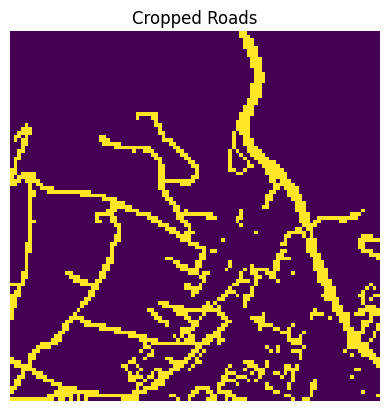

In [11]:
cropped_road = road_image.crop((x_min, y_min, min(x_max, image_width), min(y_max, image_height)))

plt.imshow(cropped_road)
plt.title('Cropped Roads')
plt.axis('off')  # Turn off axis
plt.show()

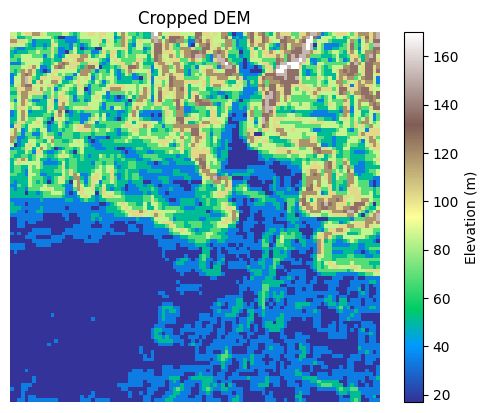

In [12]:
cropped_dem = dem_image.crop((x_min, y_min, min(x_max, image_width), min(y_max, image_height)))
cropped_dem = np.asarray(cropped_dem).copy()

plt.imshow(cropped_dem, cmap='terrain')  # Assuming 'terrain' colormap for DEM
plt.title('Cropped DEM')
plt.axis('off')  # Turn off axis
plt.colorbar(label='Elevation (m)')  # Add colorbar legend with label
plt.show()

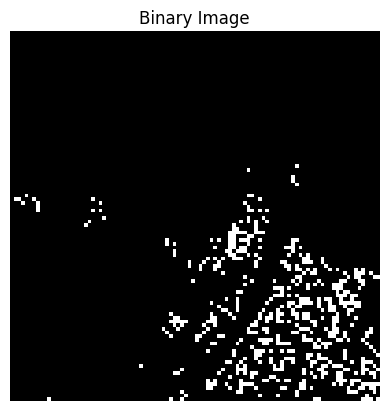

In [13]:
cropped_region = tif_image.crop((x_min, y_min, min(x_max, image_width), min(y_max, image_height)))

region = np.asarray(cropped_region).copy()

for r in range(region.shape[0]):
  for c in range(region.shape[1]):
    if region[r, c] > 0:
      region[r, c] = 1

plt.imshow(region, cmap='gray')  # Display the binary image using a grayscale colormap
plt.axis('off')  # Turn off axis
plt.title('Binary Image')  # Add a title
plt.show()

In [ ]:
def TR (coord, region):
    r = coord[0]
    c = coord[1]

    #Creating Mask
    region_temp = region[r-1:r+2, c-1:c+2].flatten()
    state = region_temp[4]
    region_temp = np.delete(region_temp, 4)

    #Transition Rules: Pixel stays alive if it has 2 or 3 alive neighbors
    if state == 1:
        if 2 <= np.count_nonzero(region_temp == 1) <= 3:
            return 1
    elif state == 0:
        if np.count_nonzero(region_temp == 1) == 3:
            return 1
    return state

In [ ]:
#Time steps
def run(steps, region):
    res = {}

    for step in range(steps):
        region_temp = region.copy()

        for r in range(1, region_temp.shape[0]-1):
            for c in range(1, region_temp.shape[1]-1):
                region_temp[r, c] = TR((r, c), region)

        region = region_temp
        res[f'{step+2024}'] = region_temp

    return res

In [ ]:
cropped = run(6, region)

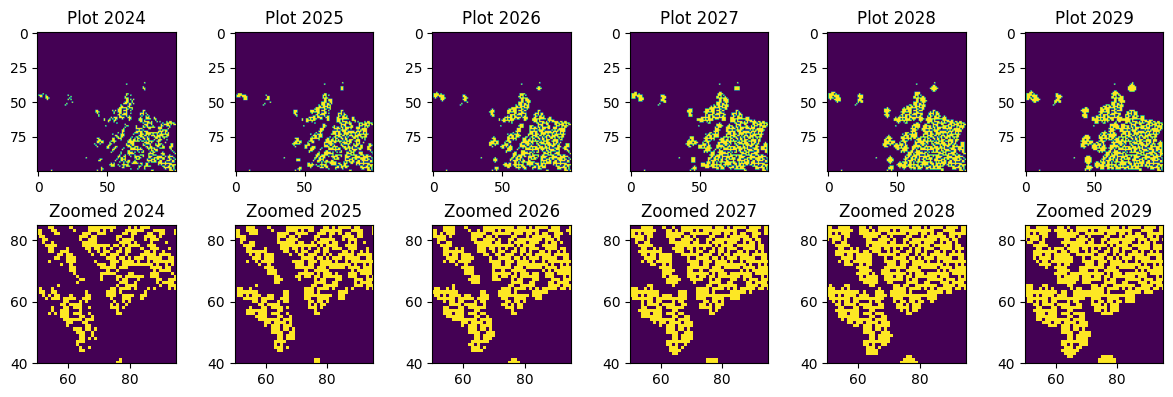

In [17]:
fig, axs = plt.subplots(nrows=2, ncols=6, figsize=(12, 4))

for i, (key, ax_col) in enumerate(zip(cropped.keys(), axs.T)):
    ax_col[0].imshow(cropped[key], cmap='viridis')
    ax_col[0].set_title(f"Plot {key}")

    ax_col[1].imshow(cropped[key], cmap='viridis')
    ax_col[1].set_title(f"Zoomed {key}")

    xlims = (50, 95)
    ylims = (40, 85)
    ax_col[1].set_xlim(xlims)
    ax_col[1].set_ylim(ylims)

plt.tight_layout()
plt.show()

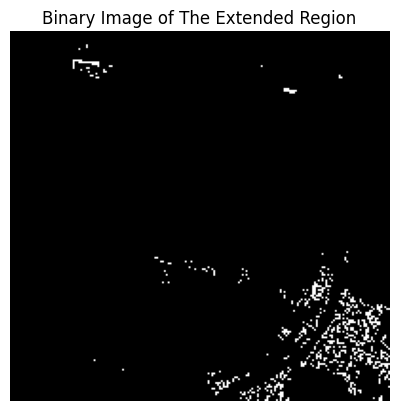

In [18]:
region_ext = np.asarray(cropped_region_ext).copy()

for r in range(region_ext.shape[0]):
  for c in range(region_ext.shape[1]):
    if region_ext[r, c] > 0:
      region_ext[r, c] = 1

plt.imshow(region_ext, cmap='gray')  # Display the binary image using a grayscale colormap
plt.axis('off')  # Turn off axis
plt.title('Binary Image of The Extended Region')  # Add a title
plt.show()

In [ ]:
cropped_ext = run(6, region_ext)

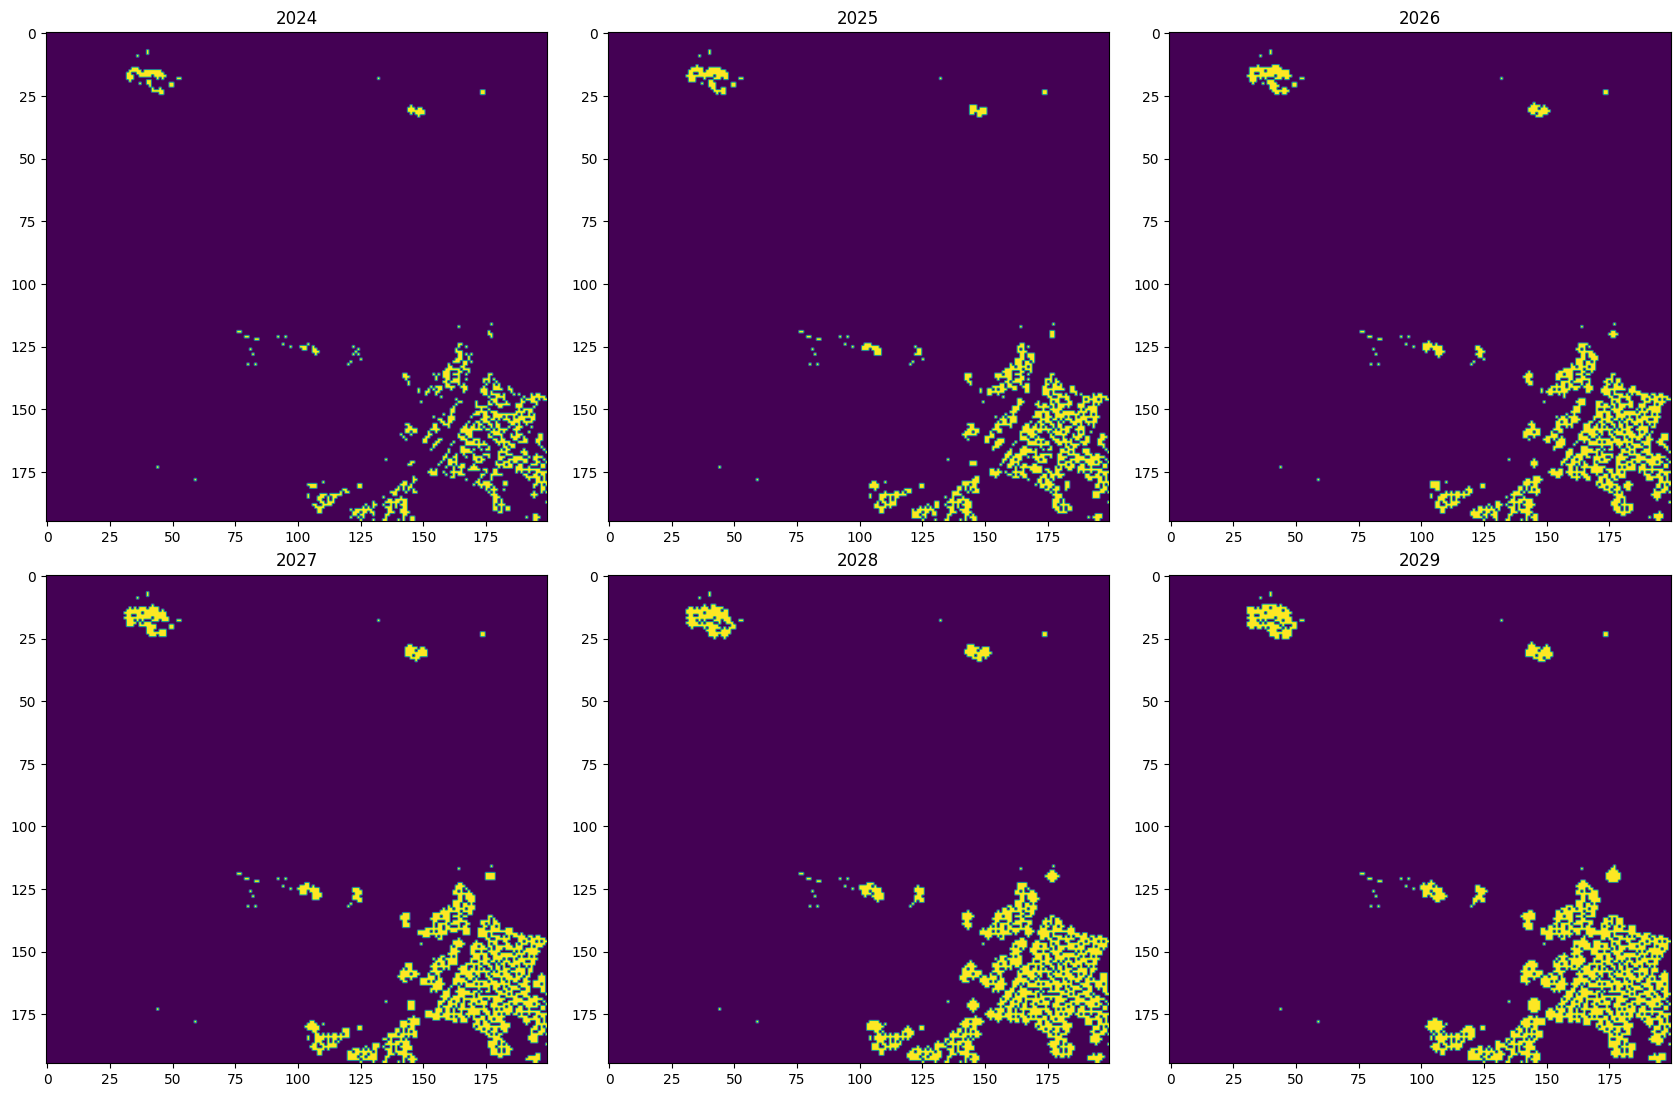

In [21]:
fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(17, 11))

for key, ax in zip(cropped_ext.keys(), axs.flatten()):
    ax.imshow(cropped_ext[key], cmap='viridis', label=f"Plot {key}")
    ax.set_title(f"{key}")

plt.tight_layout()
plt.show()

# **BUILDINGS + ROADS**

In [ ]:
from scipy.ndimage import distance_transform_edt
import matplotlib.colors as mcolors

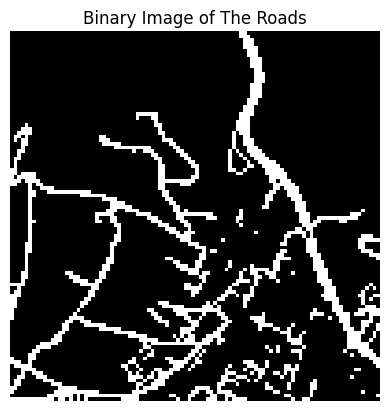

In [25]:
region_roads = np.asarray(cropped_road).copy()

for r in range(region_roads.shape[0]):
  for c in range(region_roads.shape[1]):
    if region_roads[r, c] > 0:
      region_roads[r, c] = 1

plt.imshow(region_roads, cmap='gray')
plt.axis('off')
plt.title('Binary Image of The Roads')
plt.show()

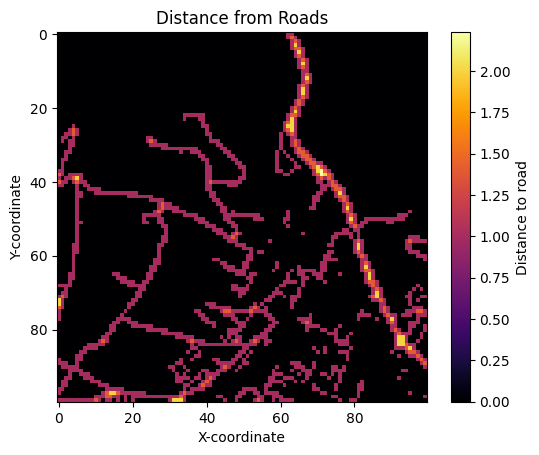

In [26]:
region_roads = region_roads.astype(bool)

distance_transform = distance_transform_edt(region_roads)

plt.imshow(distance_transform, cmap='inferno')
plt.colorbar(label='Distance to road')
plt.title('Distance from Roads')
plt.xlabel('X-coordinate')
plt.ylabel('Y-coordinate')
plt.grid(False)
plt.show()

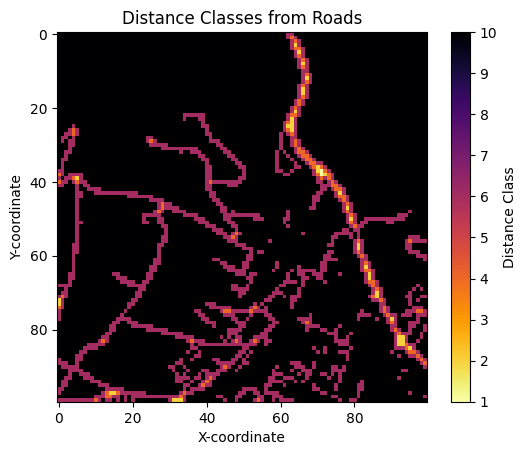

In [27]:
inferno_cmap = plt.cm.get_cmap('inferno')

inverted_inferno_cmap = inferno_cmap.reversed()

inverted_distance_transform = np.max(distance_transform) - distance_transform

num_classes = 10

bin_edges = np.linspace(0, distance_transform.max(), num_classes + 1)

distance_classes = np.digitize(inverted_distance_transform, bins=bin_edges)

plt.imshow(distance_classes, cmap=inverted_inferno_cmap, interpolation='nearest', vmin=1, vmax=num_classes)
plt.colorbar(label='Distance Class')
plt.title('Distance Classes from Roads')
plt.xlabel('X-coordinate')
plt.ylabel('Y-coordinate')
plt.grid(False)
plt.show()

In [ ]:
def TR_roads (coord, region, distance):
    r = coord[0]
    c = coord[1]

    #Creating Mask
    region_temp = region[r-1:r+2, c-1:c+2].flatten()
    state = region_temp[4]
    region_temp = np.delete(region_temp, 4)

    #Transition Rules: Pixel stays alive if it has 2 or 3 alive neighbors
    if state == 1:
        if 2 <= np.count_nonzero(region_temp == 1) <= 3 & distance[r, c] <= 3:
            return 1
    elif state == 0:
        if np.count_nonzero(region_temp == 1) == 3 or distance[r, c] < 5:
            return 1
    return state

In [ ]:
#Time steps
def run_roads(steps, region, distance):
    res = {}

    for step in range(steps):
        region_temp = region.copy()

        for r in range(1, region_temp.shape[0]-1):
            for c in range(1, region_temp.shape[1]-1):
                region_temp[r, c] = TR_roads((r, c), region, distance)

        region = region_temp
        res[f'{step+2024}'] = region_temp

    return res

In [ ]:
cropped_wroads = run_roads(6, region, distance_classes)

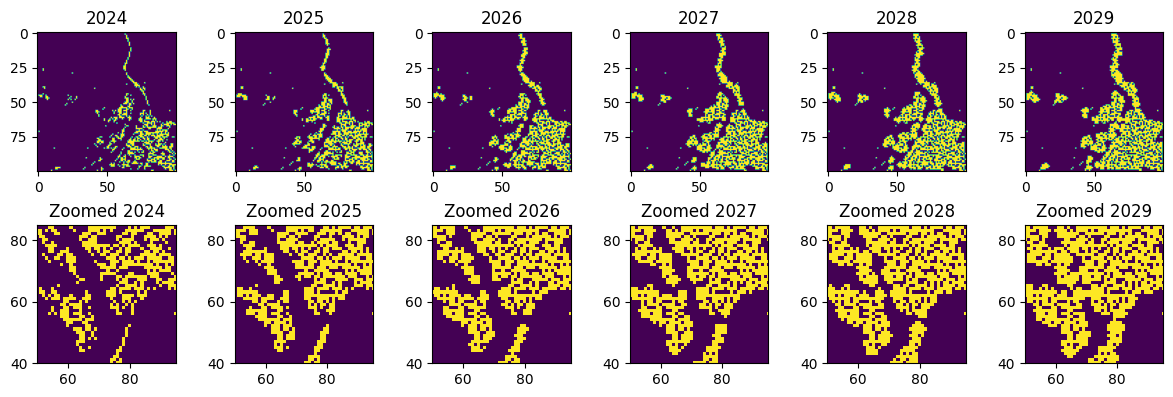

In [32]:
fig, axs = plt.subplots(nrows=2, ncols=6, figsize=(12, 4))

for i, (key, ax_col) in enumerate(zip(cropped_wroads.keys(), axs.T)):
    ax_col[0].imshow(cropped_wroads[key], cmap='viridis')
    ax_col[0].set_title(f"{key}")

    ax_col[1].imshow(cropped_wroads[key], cmap='viridis')
    ax_col[1].set_title(f"Zoomed {key}")

    xlims = (50, 95)
    ylims = (40, 85)
    ax_col[1].set_xlim(xlims)
    ax_col[1].set_ylim(ylims)

plt.tight_layout()
plt.show()

In [ ]:
region_roads_ext = np.asarray(cropped_road_image).copy()

for r in range(region_roads_ext.shape[0]):
  for c in range(region_roads_ext.shape[1]):
    if region_roads_ext[r, c] > 0:
      region_roads_ext[r, c] = 1


region_roads_ext = region_roads_ext.astype(bool)

distance_transform_ext = distance_transform_edt(region_roads_ext)

inverted_distance_transform_ext = np.max(distance_transform_ext) - distance_transform_ext

bin_edges_ext = np.linspace(0, distance_transform_ext.max(), num_classes + 1)

distance_classes_ext = np.digitize(inverted_distance_transform_ext, bins=bin_edges_ext)

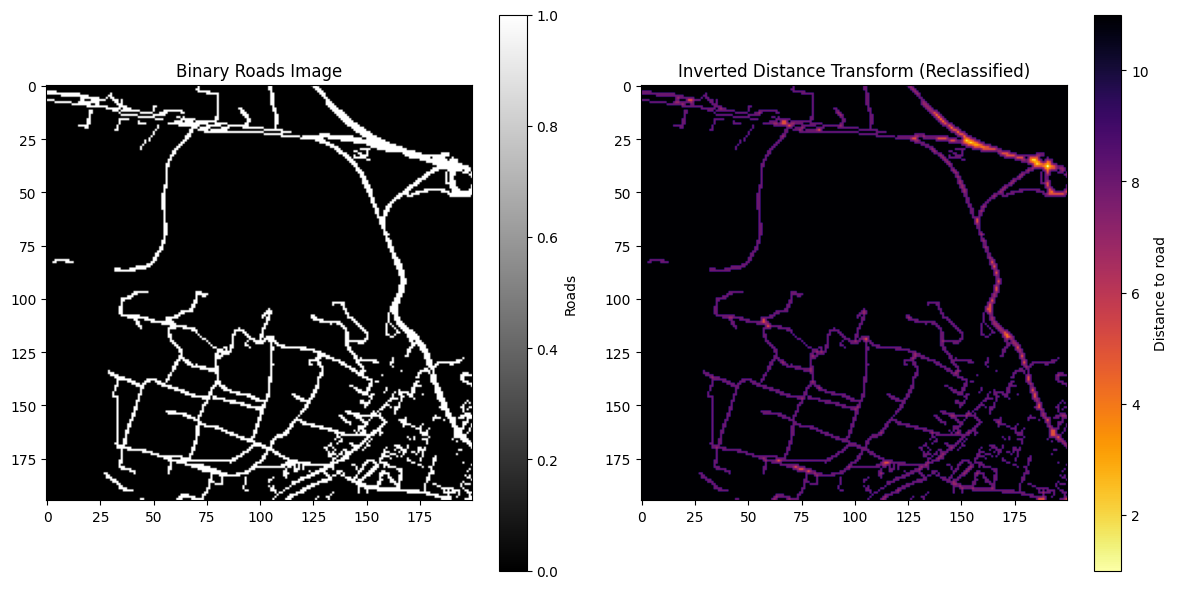

In [34]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(region_roads_ext, cmap='gray')
plt.title('Binary Roads Image')
plt.colorbar(label='Roads')

plt.subplot(1, 2, 2)
plt.imshow(distance_classes_ext, cmap=inverted_inferno_cmap)
plt.title('Inverted Distance Transform (Reclassified)')
plt.colorbar(label='Distance to road')

plt.tight_layout()
plt.show()

In [ ]:
cropped_wroads_ext = run_roads(6, region_ext, distance_classes_ext)

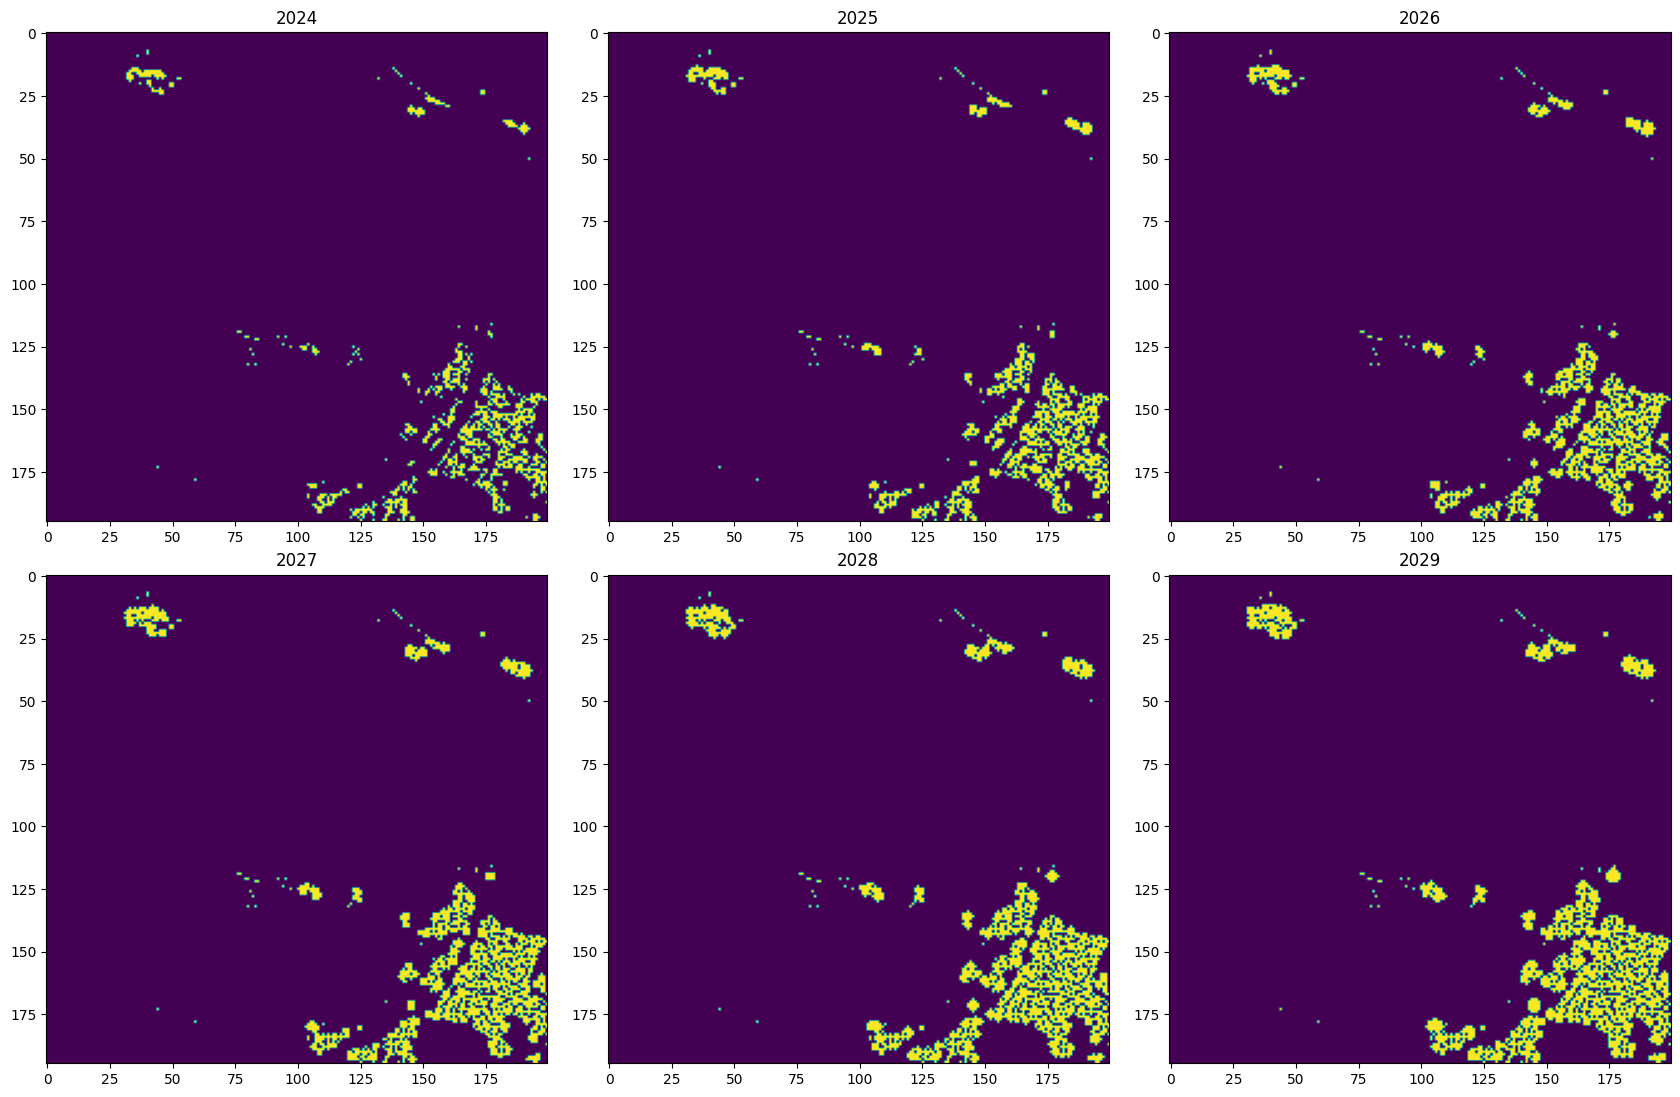

In [36]:
fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(17, 11))

for key, ax in zip(cropped_wroads_ext.keys(), axs.flatten()):
    ax.imshow(cropped_wroads_ext[key], cmap='viridis', label=f"Plot {key}")
    ax.set_title(f"{key}")

plt.tight_layout()
plt.show()

# **BUILDINGS + ROADS + DEM**

In [ ]:
def TR_roads_dem (coord, region, distance, dem):
    r = coord[0]
    c = coord[1]

    #Creating Mask
    region_temp = region[r-1:r+2, c-1:c+2].flatten()
    state = region_temp[4]
    region_temp = np.delete(region_temp, 4)

    #Transition Rules: Pixel stays alive if it has 2 or 3 alive neighbors
    if state == 1:
        if 2 <= np.count_nonzero(region_temp == 1) <= 3 & distance[r, c] <= 3:
            return 1
        elif distance[r, c] <= 3 & dem.min() <= dem[r, c] <= 80:
            return 1
        elif np.count_nonzero(region_temp == 1) == 0 & dem[r, c] > 70:
            return 0
    elif state == 0:
        if np.count_nonzero(region_temp == 1) == 3 or distance[r, c] < 5:
            return 1
        elif distance[r, c] < 5 & dem.min() <= dem[r, c] <= 70:
          return 1
    return state

In [ ]:
#Time steps
def run_roads_dem(steps, region, distance, dem):
    res = {}

    for step in range(steps):
        region_temp = region.copy()

        for r in range(1, region_temp.shape[0]-1):
            for c in range(1, region_temp.shape[1]-1):
                region_temp[r, c] = TR_roads_dem((r, c), region, distance, dem)

        region = region_temp
        res[f'{step+2024}'] = region_temp

    return res

In [ ]:
cropped_w_roads_dem = run_roads_dem(6, region, distance_classes, cropped_dem)

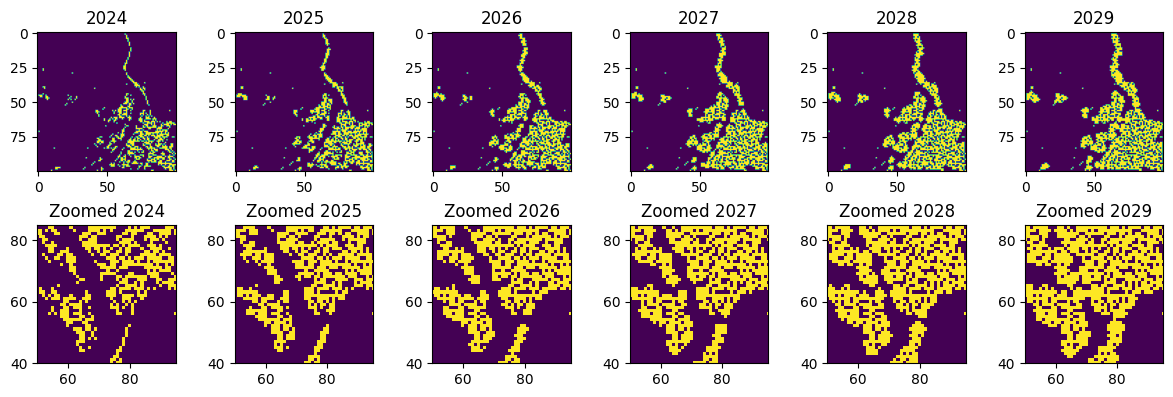

In [40]:
fig, axs = plt.subplots(nrows=2, ncols=6, figsize=(12, 4))

for i, (key, ax_col) in enumerate(zip(cropped_w_roads_dem.keys(), axs.T)):
    ax_col[0].imshow(cropped_w_roads_dem[key], cmap='viridis')
    ax_col[0].set_title(f"{key}")

    ax_col[1].imshow(cropped_w_roads_dem[key], cmap='viridis')
    ax_col[1].set_title(f"Zoomed {key}")

    xlims = (50, 95)
    ylims = (40, 85)
    ax_col[1].set_xlim(xlims)
    ax_col[1].set_ylim(ylims)

plt.tight_layout()
plt.show()

In [ ]:
cropped_dem_ext = np.asarray(cropped_dem_image).copy()
cropped_w_roads_dem_ext = run_roads_dem(6, region_ext, distance_classes_ext, cropped_dem_ext)

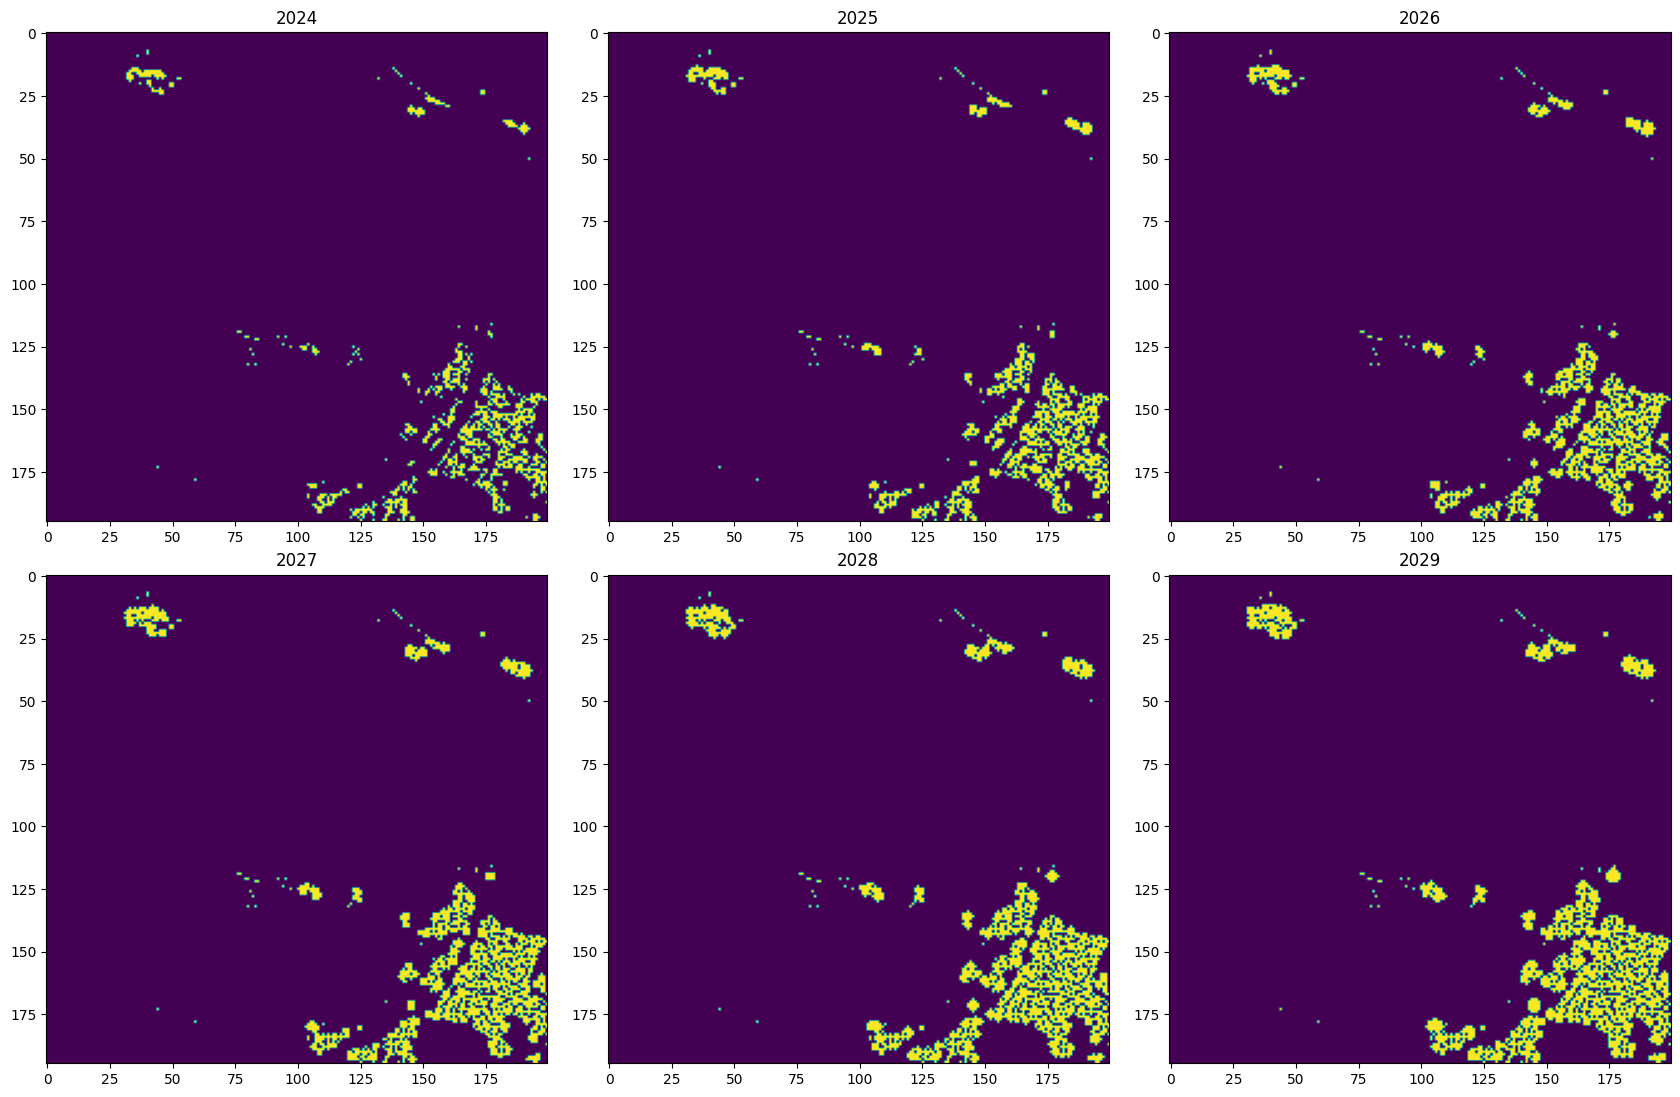

In [42]:
fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(17, 11))

for key, ax in zip(cropped_w_roads_dem_ext.keys(), axs.flatten()):
    ax.imshow(cropped_w_roads_dem_ext[key], cmap='viridis', label=f"Plot {key}")
    ax.set_title(f"{key}")

plt.tight_layout()
plt.show()

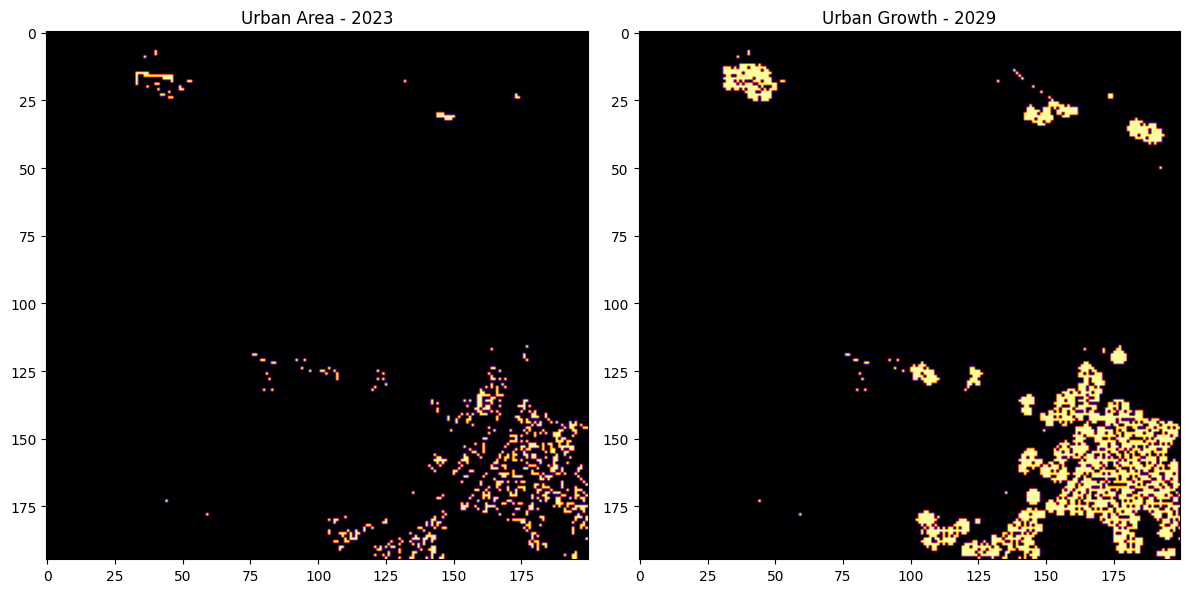

In [43]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cropped_region_ext, cmap='inferno')
plt.title('Urban Area - 2023')

plt.subplot(1, 2, 2)
plt.imshow(cropped_w_roads_dem_ext['2029'], cmap='inferno')
plt.title('Urban Growth - 2029')

plt.tight_layout()
plt.show()